# Segment subject brain according to the MultiConn atlas

To use the MultiConn atlas, one must segment individual brains according to the parcellation used in [Alemán-Gómez et. al 2022](https://www.nature.com/articles/s41597-022-01624-8).

The MultiConn's parcellation is a combination of the cortical parcellation from [Cammoun et al. 2012]() and the subcortical parcellation from [Battistella et al. 2016](https://link.springer.com/article/10.1007/s00429-016-1336-4).

In this notebook, we first generate the cortical and subcortical parcellations, and then use the Parcellation class to combine both into the MultiConn's parcellation.

<img src="../../../img/multiconn.png">

## 📦 Imports

In [1]:
import mindmap as mm

# get readers
data_manager = mm.io.TutoManager("../../config.yml")
sub_reader   = data_manager.get_subject("intra-12")
std_reader   = data_manager.get_standards()

## 🧠 Data

**Anatomy**
- T1

**Standardized data**
- Left hemisphere Lausanne 2018 annotation.
- Right hemisphere Lausanne 2018 annotation.
- MNI template.
- Thalamic Nuclei atlas.

<br>Standardized data files needs to be stored in the configuration file. There is no nead to load the data in the Notebook as everything will be loaded via the `parcellate_{name}()` functions.

In [2]:
# # ------------ Parameters -------------
# fconfig = "../../papers/simf/configuration.yml"
# # -------------------------------------

# # configuration
# config = mm.io.read_config(fconfig)

# # Subject names
# print(f"Data set name: {config['NAME']}")
# print(f"List of subjects: {config['SUBS']}")

## ⚙️ Parcellate according to the MultiConn atlas

📥 **<font color=pink>Inputs</font>**
<br>**data**:
- `T1`: T1-weighted MRI.

<br>**Standardized data**
- Left hemisphere Lausanne 2018 annotation.
- Right hemisphere Lausanne 2018 annotation.
- MNI template.
- Thalamic Nuclei atlas.

📥 **<font color=pink>Outputs</font>**
- `parc`: Parcellation

Let's perform parcellation according to the MultiConn Atlas (2022). The `parcellate_multiconn()` function first parcellates the brain using the Lausanne 2018 atlas (see `parcellate_lausanne2018()`) and then applies the thalamic nuclei atlas (see `parcellate_thal()`). Finally, it fuses the thalamic nuclei into the initial parcellation.

🎚️ **<font color=pink>MultiConn Parcellation</font>**:
- `sub`: Subject name as appearing in the FreeSurfer directory.
- `margin`: Margin in [mm] to extend regions inside the white matter, this garantees that points on the white surface (where dipoles will be) belong to a region.
- `thresh`: Probability threshold to discretize probability parcellations (such as the Thalamic parcellation).

In [5]:
sub_reader.sub

'intra-12'

In [6]:
# white matter extension in [mm]
margin = 2

# probability threshold to discretize probability atlas (thalamus atlas) 
thresh = 0.05

# create parcellation
parc = mm.anatomy.parcellation.parcellate_multiconn(
    sub     = sub_reader.sub,
    fconfig = data_manager.config,
    margin  = margin,
    thresh  = thresh,
    verbose = 1,
)

Segmenting subject intra-12 according to the Lausanne 2018 atlas ...
Loading data ...


NameError: name 'dataset_reader' is not defined

In [14]:
# ------------ Parameters -------------
sub    = config["SUBS"][0]
margin = 2
thresh = 0.05
# -------------------------------------

parc  = mm.head.parcellate_multiconn(sub, fconfig, margin=margin, thresh=thresh, verbose=1)
image = parc.get_image()

Segmenting subject vepcon_sub-10 according to the Lausanne 2018 atlas ...
Loading data ...
DATA SUMMARY
Dataset: simf
Subject: vepcon_sub-10
Retrieved objects:
- std-ctx
Missing objects:
Registering surface-based segmentation ...
Expanding surface-based segmentation to volumetric segmentation ...
Fixing FreeSurfer color LUT ...
Deleting Temporary files ...
Lausanne Parcellation of subject vepcon_sub-10 finished
Segmenting subject vepcon_sub-10 according to the thalamic atlas ...
Loading data ...
DATA SUMMARY
Dataset: simf
Subject: vepcon_sub-10
Retrieved objects:
- T1
- std-thal
- std-mni
- std-thalclut
Missing objects:
ANTS registration of MNI space ...
Thalamic Parcellation of subject vepcon_sub-10 finished
MultiConn parcellation of subject vepcon_sub-10 finished


📊 **Parcellation** <br>

🎚️ **<font color=pink>Show slices</font>**:
- `slices`: MRI slices to visualize.

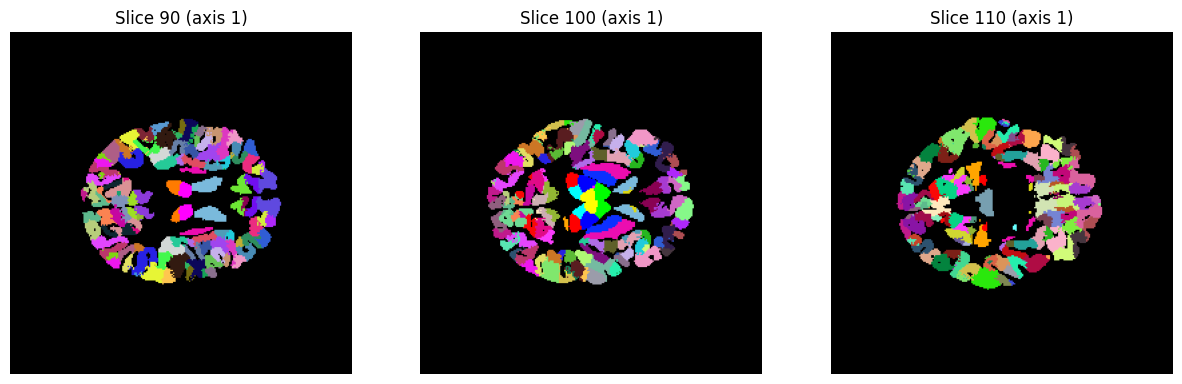

In [16]:
# ------------ Parameters -------------
slices = [90, 100, 110]
# -------------------------------------

mm.viz.show_slices(image, slices, axis=1)


💾 **Saving parcellation**

In [19]:
folder = config["MM_DIR"]/sub/"parc"
if folder.exists() == False:
    folder.mkdir(parents=True)

generic_name = f"{sub}_space-T1w_atlas-MultiConn2022_desc-scale4_dseg"

print(f"Saving MultiConn parcellation for subject: {sub}")
parc.save(
    folder/(generic_name+".nii.gz"),
    folder/(generic_name+".txt"),
)

Saving MultiConn parcellation for subject: vepcon_sub-10
